In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.manifold import TSNE

In [4]:
df = pd.read_csv(r"C:\Users\PGCP-AI.STUDENTSDC\Desktop\Machine_Learning\Cases\Wisconsin\BreastCancer.csv",index_col=0)
df.sample(5)

,Clump,UniCell_Size,Uni_CellShape,MargAdh,SEpith,BareN,BChromatin,NoemN,Mitoses,Class
Code,,,,,,,,,,
1173347,8,3,3,1,2,2,3,2,1,Benign
1306282,6,6,7,10,3,10,8,10,2,Malignant
1182404,4,2,1,1,2,1,1,1,1,Benign
191250,10,4,4,10,2,10,5,3,3,Malignant
1299924,3,2,2,2,2,1,4,2,1,Benign


In [5]:
X , y = df.drop('Class',axis=1) , df['Class']

In [6]:
tsne = TSNE(random_state=26).set_output(transform='pandas')
t_comps = tsne.fit_transform(X)

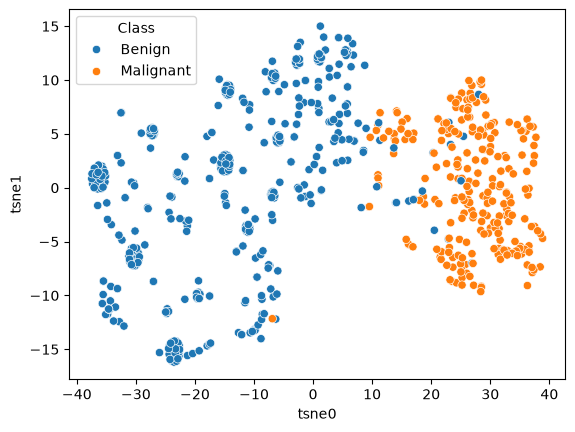

In [9]:
t_comps['Class'] = y
sns.scatterplot(t_comps,x='tsne0',y='tsne1',hue='Class')
plt.show()

# Exercise

In [12]:
df = pd.read_csv(r"C:\Users\PGCP-AI.STUDENTSDC\Desktop\Machine_Learning\Cases\Vehicle Silhouettes\Vehicle.csv")
df.sample(5)

,Comp,Circ,D.Circ,Rad.Ra,Pr.Axis.Ra,Max.L.Ra,Scat.Ra,Elong,Pr.Axis.Rect,Max.L.Rect,Sc.Var.Maxis,Sc.Var.maxis,Ra.Gyr,Skew.Maxis,Skew.maxis,Kurt.maxis,Kurt.Maxis,Holl.Ra,Class
212,90,41,71,169,68,7,150,44,19,138,175,336,157,71,3,18,192,197,bus
325,82,44,63,123,54,7,151,45,19,147,166,329,185,81,3,4,179,182,bus
844,86,36,78,146,58,7,135,50,18,124,155,270,148,66,0,25,190,195,saab
284,89,46,77,125,52,10,156,44,20,160,171,351,177,78,7,17,183,191,van
471,104,55,109,230,67,12,218,30,24,174,230,706,226,67,8,22,191,202,opel


In [31]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X , y = df.drop('Class',axis=1) , df['Class']
X_scal = scaler.fit_transform(X)

In [32]:
tsne = TSNE(random_state=26).set_output(transform='pandas')
t_comps = tsne.fit_transform(X_scal)

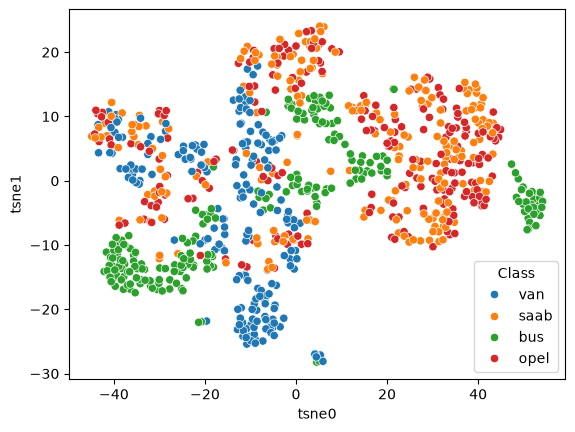

In [33]:
t_comps['Class'] = y
sns.scatterplot(t_comps,x='tsne0',y='tsne1',hue='Class')
plt.show()

In [20]:
from sklearn.decomposition import PCA
prcmp = PCA().set_output(transform='pandas')
p_comps = prcmp.fit_transform(X)

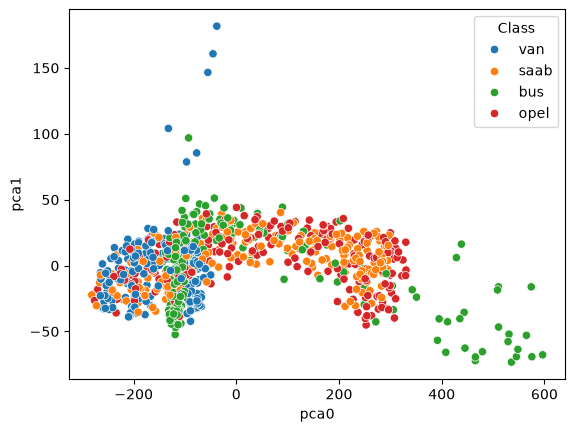

In [22]:
p_comps['Class'] = y
sns.scatterplot(p_comps,x='pca0',y='pca1',hue='Class')
plt.show()

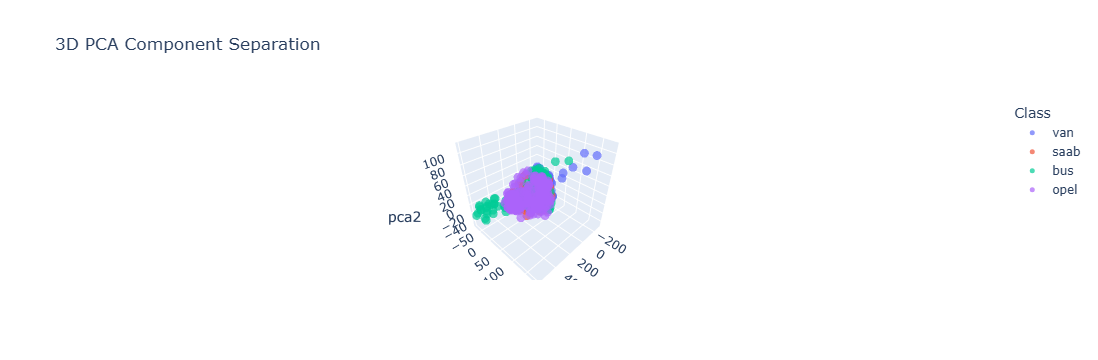

In [25]:
import pandas as pd
import plotly.express as px

fig = px.scatter_3d(
    p_comps, 
    x='pca0', y='pca1', z='pca2',
    color='Class',
    title='3D PCA Component Separation',
    opacity=0.7,
    labels={'PC1': 'Component 1', 'PC2': 'Component 2', 'PC3': 'Component 3'}
)

fig.update_traces(marker=dict(size=5))
fig.show()
